# Heart Disease Predictor (Artificial Neural Networks - ANNs or Multilayer Perceptron - MLP)

### 1) Import Libraries 

In [2]:
# Import libraries and modules

# ---------- path setup ----------
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.insert(0, str(PROJECT_ROOT / "Notebooks"))
DATA_DIR = PROJECT_ROOT / "Data/heartdisease_dataset"
OUT_DIR = PROJECT_ROOT / "Outputs/cls_mlp"; OUT_DIR.mkdir(exist_ok=True)
OUT_DIR_FIG = PROJECT_ROOT / "Outputs/cls_mlp_fig"

#----- Tools, visualizers -----
from utils import *
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest, loguniform
from scipy import stats
import seaborn as sns
import numpy as np
import joblib
import time

#----- Preprocessing, Neural Networks -----
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score, classification_report, \
confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, recall_score, \
precision_score, average_precision_score, brier_score_loss
import tensorflow as tf
tf.keras.utils.set_random_seed(42)                                  # seed python, numpy & TF
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.metrics import fbeta_score
from sklearn.calibration import calibration_curve
import warnings; warnings.filterwarnings("ignore")
from tabpfn import TabPFNClassifier


### 2) Load Data

In [3]:
# Load train set
#---------------
data = pd.read_csv(DATA_DIR / "train_set.csv")
test = pd.read_csv(DATA_DIR / "test_set.csv")

data.shape, test.shape

((780, 12), (138, 12))

In [4]:
data

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,43,M,ASY,132,247,1,LVH,143,Y,0.1,Flat,1
1,68,M,NAP,118,277,0,Normal,151,N,1.0,Up,0
2,57,M,ASY,132,207,0,Normal,168,Y,0.0,Up,0
3,60,M,ASY,130,206,0,LVH,132,Y,2.4,Flat,1
4,50,F,ASY,160,0,1,Normal,110,N,0.0,Flat,1
...,...,...,...,...,...,...,...,...,...,...,...,...
775,46,M,NAP,120,230,0,Normal,150,N,0.0,Up,0
776,71,M,ASY,130,221,0,ST,115,Y,0.0,Flat,1
777,61,M,ASY,134,0,1,ST,86,N,1.5,Flat,1
778,61,M,ASY,125,292,0,ST,115,Y,0.0,Up,0


### 3) Split Data
Before preprocessing and model training, we need to split the dataset into **train** and **validation** sets.  
- The **training set** is used to learn the patterns.  
- The **validation set** is used to evaluate performance on unseen data, preventing overfitting.  

In [4]:
# Split dataset into train and validation sets
#----------------------------------------------

# Set random state
RANDOM_STATE = 42

# Separate features and labels cols
X = data.drop(columns='HeartDisease') # Features
y = data['HeartDisease'] # Labels

# Split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2 , random_state=RANDOM_STATE, stratify=y
)

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | y_train: {y_train.shape} | y_val: {y_val.shape}")
print("----Done----")

X_train: (624, 11) | X_val: (156, 11) | y_train: (624,) | y_val: (156,)
----Done----


### Preprocessing
Preprocessing ensures that the dataset is clean, consistent, and suitable for Neural Networks.  
In this project, our preprocessing will focus on:  
1. **Handling invalid values**  
   - *RestingBP*: drop rows with 0 (impossible value).  
   - *OldPeak*: replace negative values with 0 (invalid in medical context).  
   - *Cholesterol*: treat 0 as missing values and impute instead of dropping (since there are many).  

2. **Imputation**  
   - For *Cholesterol*, we will impute missing/invalid values.  
   - Options: Mean, Median, or Model-based imputation.  
   - For this project, we will start simple (Median/Mean) then we can test Model-based imputations to compare performance.  

3. **Scaling / Standardization**  
   - Many ML models (e.g., Logistic Regression, SVM, KNN) require features to be on similar scales.  
   - We will apply **StandardScaler** or **MinMaxScaler** depending on the model. 
        - For ANNs we need to scale the values in a specific range (e.g. [0,1]), **MinMaxScaler** is the ideal choice in this case.
 
4. **Encoding categorical features**  
   - Convert categorical variables into numeric form using **One-Hot Encoding** or **Label Encoding** depending on the situation.  

5. *(Optional)* Handling skewness and outliers  
   - For this project, we will skip skewness/outlier handling, since:  
     - Skewness may only affect specific models.  
     - Outliers in medical datasets may represent real patients and should not always be removed.  
 
6. *(Optional)* Convert dataframes into numpy arrays to be fed into the networks.


---


### 4) Core of preprocessing and handling data
> Including 3-5 steps mentioned above.

### - Pipeline Approach

##### 1 - Cleanup Operations

In [5]:
"""
Three continuous numeric features were spotted having INVALID,
 IMPOSSIBLE vlues BIOLOGICLY & in terms of MEDICAL SCIENCE
 * RestingBP -> 1 case with the value 0 (since it's only one case it's better to be removed)
 * OldPeak -> 13 cases with negative values (there are atleast two ways to consider)
    - Replacing negative values with the baseline which is 0 (clipping)
    - Using median imputation
    -> First option is reasonable since number of cases is low
 * Cholesterol -> 172 cases with the value 0 (almost 20% of values)
 - Zeros can be considered as missing values and be imputed by using median/mean or Model-based techniques
"""

#---------------------------------------------------------------------------------------
# - RestingBP invalid values handling: 
#   Because this part will change the number of rows and values 
#   of the target col SO we need to implement it outside Pipeline 
#   to not run into any problem (This cell)

# - OldPeak and Cholesterol invalid values handling: 
#   OldPeak gets filtered and negative values will be replaced 
#   with zero, Cholesterol's zero values will be converted into 
#   Nan so that they all will be preprocessed consistently inside pipeline (Next cells)
#----------------------------------------------------------------------------------------

# -----RestingBP-----

#  Train
#--------------
# Filter X_train & y_train
X_train, y_train = drop_invalid_resting_bp(X_train, y_train)

#  Validation
#---------------
# Filter X_val & y_val
X_val, y_val = drop_invalid_resting_bp(X_val, y_val)


print("-----Done-----")


-----Done-----


In [6]:
# Development set = all training data (the test set stays locked)
X_dev = pd.concat([X_train, X_val]).reset_index(drop=True)
y_dev = pd.concat([y_train, y_val]).reset_index(drop=True)
print(X_dev.shape, y_dev.mean().round(3))

(779, 11) 0.553


##### 2 - Check Outliers & Skewness
Checking outliers and skewness after cleanup operations

In [7]:
f = X_train[['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']]

# Check outliers of X_train after cleanup operation to decide which scaler to use
# Safe zone -> outliers < 5%
df_out = outlier_detector(f)

# Check skewness of X_train after cleanup operation
df_sk  = skewness_detector(f)

# Combine into one overview DataFrame
df_summary = pd.concat([df_out, df_sk], axis=1).reset_index(drop=True)

print("Outlier & Skewness Summary (before scaling):")
df_summary.iloc[:, [0,1,2,4,5]] # Drop the second Feature column in df


Outlier & Skewness Summary (before scaling):


,Feature,N_outliers,Outlier_pct,Skewness,Skewness_Exceeding_Threshold
0,Cholesterol,117,18.780,0.849803,False
1,RestingBP,19,3.050,0.632721,False
2,Oldpeak,12,1.926,0.605256,False
3,MaxHR,1,0.161,0.234924,False
4,Age,0,0.000,0.126842,False


##### 3 - The full preprocessing pipeline

In [8]:
"""
Continuous numeric features should be scaled and standardized
* Including Features: [Age, RestingBP, Cholesterol, MaxHR, Oldpeak]
* First option for sclaing technique is `MinMaxScaler` 
============================================================================================
Categorical features that aren't continuous numeric type should be encoded to
numerical types.
* Including Features: [Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope]
* `FastingBS` was excluded since it's already numeric (binary: 0s 1s), but should be added to the pipeline.
* The encoders could be used are:
- One-Hot Encoding-> For binary categories
- One-Hot Encoding -> For nominal (no order) or Ordinal (ordered) categories
- Ordinal Encoding -> For ordinal (ordered) categories
* In our case for the features, all of encoders can be used for the corresponding categories:
- Sex, ExerciseAngina, FastingBS (Binary) => Label Encoder
- ChestPainType, RestingECG (Nominal) => One-Hot Encoder
- ST_Slope (Ordinal) => Ordinal  or One-Hot Encoding
"""

# Identify columns
#------------------

# Continuous numeric features
con_num_features = ['Age', 'RestingBP', 'MaxHR', 'Cholesterol', 'Oldpeak']

# Categorical features
bin_features = ['Sex', 'ExerciseAngina', 'FastingBS']
nom_features = ['ChestPainType', 'RestingECG']
ord_features = ['ST_Slope']


# Continuos numeric Pipelines
#------------------------------

# Continuous numeric Pipeline 
con_num_Pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])


# Categorical Pipelines
#------------------------------

# Binary features Pipeline
bin_Pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("oe_encoder", OrdinalEncoder())
])

# Nominal features Pipeline
nom_Pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe_encoder", OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])

# Ordinal features Pipeline
ord_Pipeline = Pipeline(([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("oe_encoder", OrdinalEncoder(categories=[['Down', 'Flat', 'Up']]))
]))


# Combine all Pipelines to build the full preprocessor
#------------------------------------------------------

# The column transformer to perform feature engineering (including all features except 'Oldpeak' & 'Cholesterol')
preprocessor = ColumnTransformer([
    ("con_num", con_num_Pipeline, con_num_features),
    ("bin", bin_Pipeline, bin_features),
    ("nom", nom_Pipeline, nom_features),
    ("ord", ord_Pipeline, ord_features)
], remainder="drop")

# Full preprocessing pipeline: clean columns first, then feature engineering
full_preprocessor = Pipeline([
    ("clean_columns", MedicalColumnCleaner(oldpeak_col='Oldpeak', cholesterol_col='Cholesterol')),
    ("feature_engineering", preprocessor)
])

print("-----Preprocessing with pipeline done-----", end="\n\n")


-----Preprocessing with pipeline done-----



### 5) Build the architecture and model (A simple prototyping arch)


#### - Fit the preprocessor and transform

In [9]:

# 1. Fit the sklearn preprocessor on training features
full_preprocessor.fit(X_train)                       # X_train: pandas.DataFrame

# 2. Transform -> get NumPy arrays
X_train_proc = full_preprocessor.transform(X_train)  # usually numpy array
X_val_proc   = full_preprocessor.transform(X_val)

# 3. Ensure dtypes and shapes are correct for TF
X_train_proc = X_train_proc.astype(np.float32)
X_val_proc   = X_val_proc.astype(np.float32)

# 4. Convert labels to numpy (ints)
y_train_np = np.array(y_train).astype(np.int32).reshape(-1,)
y_val_np   = np.array(y_val).astype(np.int32).reshape(-1,)


print("----- Fitting & Transforming done -----")


----- Fitting & Transforming done -----


#### - Train with internal validation split (no X_val in callbacks)

In [11]:
#---------------------------------------------------------------------
# Build the architecture, model and fit, train, internal evaluation
#---------------------------------------------------------------------

# Build Keras model with the right input shape
input_dim = X_train_proc.shape[1] # = 16

model = tf.keras.models.Sequential([
    # Input layer
    tf.keras.layers.Input(shape=(input_dim,)),
    # First hidden layer with 16 units
    tf.keras.layers.Dense(16, activation='relu'),
    # Second hidden layer with 16 units 
    tf.keras.layers.Dense(8, activation='relu'),
    # Set dropout to prevent overfitting
    tf.keras.layers.Dropout(0.3),
    # Third hidden layer with 1 unit (output layer)
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compile
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Stop early if validation loss doesn’t improve for 5 epochs
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
#ckpt = tf.keras.callbacks.ModelCheckpoint("ANN_best.keras", monitor='val_loss', save_best_only=True, verbose=1)

# 6. Fit using numpy arrays
history = model.fit(
    X_train_proc, y_train_np,
    epochs=30,
    validation_split=0.2,          # use part of training data for validation:
    callbacks=[early_stop],        #(we don't use X_val_proc becuase we don't want the model to see it and cuasees data leakage)
)

# 7. Evaluate during training
model.evaluate(X_val_proc, y_val_np, verbose=2)


Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.5622 - loss: 0.7407 - val_accuracy: 0.5200 - val_loss: 0.7275
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5582 - loss: 0.7056 - val_accuracy: 0.5200 - val_loss: 0.6945
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5562 - loss: 0.6633 - val_accuracy: 0.5200 - val_loss: 0.6734
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5663 - loss: 0.6483 - val_accuracy: 0.5200 - val_loss: 0.6569
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5602 - loss: 0.6256 - val_accuracy: 0.5200 - val_loss: 0.6418
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5904 - loss: 0.6237 - val_accuracy: 0.5280 - val_loss: 0.6240
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6245 - loss: 0.6073 - val_accuracy: 0.5440 - val_loss: 0.6068
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6406 - loss: 0.5818 - val_accuracy: 0.5920 - v

[0.468168169260025, 0.8397436141967773]

#### - Plot accuracy/loss graphs (internal evaluation)

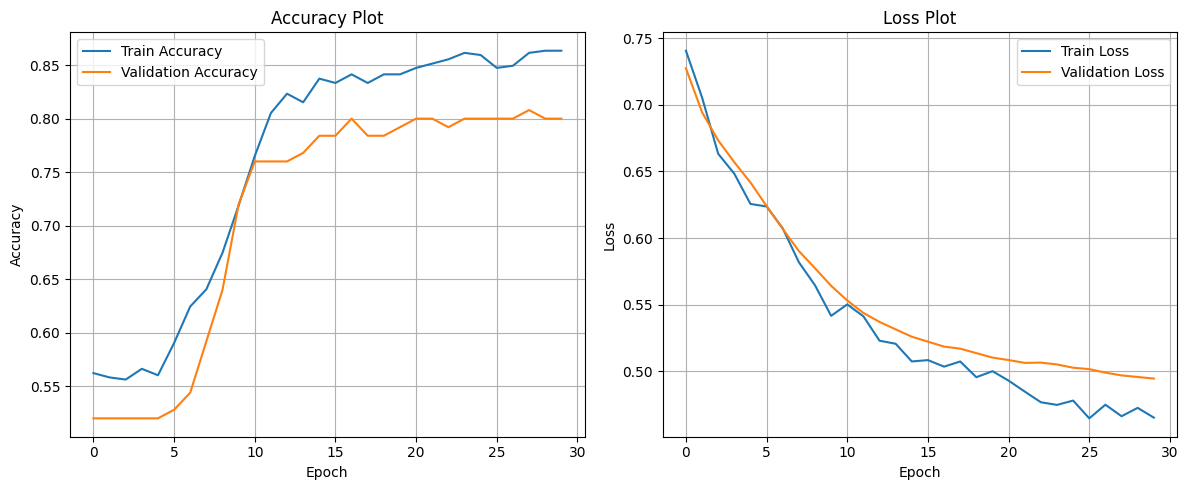

In [12]:
#---------------------------------------------------------------------
# Visualize performance of the model during training (Internal eval)
#---------------------------------------------------------------------
def plot_accuracy_loss(history):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Accuracy comparison
    axes[0].plot(history.history['accuracy'], label="Train Accuracy")
    axes[0].plot(history.history['val_accuracy'], label="Validation Accuracy")
    axes[0].set_title("Accuracy Plot")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid()
    axes[0].legend()

    # Loss comparison
    axes[1].plot(history.history['loss'], label="Train Loss")
    axes[1].plot(history.history['val_loss'], label="Validation Loss")
    axes[1].set_title("Loss Plot")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].grid()
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_accuracy_loss(history)

### 6) Cross-validated evaluation of the ANN/MLP


In [13]:
#--------------------------------------------------------
# Wrapper to use the Keras MLP inside sklearn pipelines & CV
#--------------------------------------------------------

class KerasMLP(ClassifierMixin, BaseEstimator):
    def __init__(self, units1=16, units2=8, dropout=0.3, lr=1e-3, batch_size=32, epochs=100, patience=10, seed=42):
        self.units1 = units1; self.units2 = units2; self.dropout = dropout; self.lr = lr
        self.batch_size = batch_size; self.epochs = epochs; self.patience = patience; self.seed = seed

    def fit(self, X, y):
        tf.keras.utils.set_random_seed(self.seed)                      # same seed on every fit
        X = np.asarray(X, dtype="float32"); y = np.asarray(y).astype("int32")
        # Hold out 15% of the training data for early stopping (stratified, shuffled)
        X_tr, X_es, y_tr, y_es = train_test_split(X, y, test_size=0.15, stratify=y, random_state=self.seed)

        self.model_ = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(X.shape[1],)),
            tf.keras.layers.Dense(self.units1, activation='relu'),
            tf.keras.layers.Dense(self.units2, activation='relu'),
            tf.keras.layers.Dropout(self.dropout),
            tf.keras.layers.Dense(1, activation='sigmoid')
        ])
        self.model_.compile(optimizer=tf.keras.optimizers.Adam(self.lr), loss='binary_crossentropy', metrics=['accuracy'])
        early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=self.patience, restore_best_weights=True)
        self.history_ = self.model_.fit(X_tr, y_tr, validation_data=(X_es, y_es), epochs=self.epochs,
                                        batch_size=self.batch_size, callbacks=[early_stop], verbose=0)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = self.model_.predict(np.asarray(X, dtype="float32"), verbose=0).ravel()
        return np.column_stack([1 - p, p])                               # sklearn wants both classes

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


# Same CV settings as the ML notebook (same random_state => same outer folds)
nested_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "f1_w": "f1_weighted", "recall": "recall", "precision": "precision", "ap": "average_precision"}


In [ ]:
# Paired comparison (Nadeau-Bengio corrected t-test), same function as before
def nb_paired(a, b):
    d = np.asarray(b) - np.asarray(a); k = len(d)
    se = np.sqrt((1/k + 0.25) * d.var(ddof=1))
    t = d.mean() / se; p = 2 * stats.t.sf(abs(t), k - 1)
    return d.mean(), p

In [ ]:
# Quick check of the wrapper before the long runs

t0 = time.perf_counter()
smoke = Pipeline([("preproc", full_preprocessor), ("model", KerasMLP(epochs=5))]).fit(X_dev, y_dev)
print(f"One fit (5 epochs): {time.perf_counter() - t0:.1f} s")

p = smoke.predict_proba(X_dev)
print(p.shape, p[:3].round(3))                                       # expect (779, 2)
print(clone(smoke.named_steps["model"]).get_params())                # clone must work (needed by CV)

One fit (5 epochs): 4.6 s
(779, 2) [[0.176 0.824]
 [0.405 0.595]
 [0.39  0.61 ]]
{'batch_size': 32, 'dropout': 0.3, 'epochs': 5, 'lr': 0.001, 'patience': 10, 'seed': 42, 'units1': 16, 'units2': 8}


In [16]:
# Save per-fold AUCs & out-of-fold probabilities (this notebook is compared against them)
CLS_ML = PROJECT_ROOT / "Outputs/cls_ml"
nested_store = joblib.load(CLS_ML / "nested_store.joblib")
ens_cv = joblib.load(CLS_ML / "ens_cv.joblib")
oof = joblib.load(CLS_ML / "oof.joblib")

fold_auc = {n: nested_store[n]["test_roc_auc"] for n in nested_store}
fold_auc.update({f"{n} (ensemble)": ens_cv[n]["test_roc_auc"] for n in ens_cv})
pd.DataFrame(fold_auc).to_csv(OUT_DIR / "cls_fold_auc.csv", index=False)
pd.DataFrame({**{n: oof[n][0] for n in oof}, "y": oof["Stacking"][1]}).to_csv(OUT_DIR / "cls_oof_probs.csv", index=False)

In [17]:
#--------------------------------------------------------
# MLP (original architecture) in the outer CV folds - no tuning
#--------------------------------------------------------

# Fold matching only works if X_dev has the same row order as in the ML notebook
y_ml = pd.read_csv(OUT_DIR / "cls_oof_probs.csv")["y"].values[:len(y_dev)]
assert (y_ml == y_dev.values).all(), "X_dev order differs from the ML notebook"

ann_pipe = Pipeline([("preproc", full_preprocessor), ("model", KerasMLP(seed=RANDOM_STATE))])
r_ann_def = cross_validate(ann_pipe, X_dev, y_dev, cv=nested_cv, scoring=scoring, n_jobs=1, verbose=2)
joblib.dump(r_ann_def, OUT_DIR / "r_ann_def.joblib")            # save right away
print("Default MLP AUC:", r_ann_def["test_roc_auc"].mean().round(4), "+/-", r_ann_def["test_roc_auc"].std().round(4))

[CV] END .................................................... total time=  27.1s
[CV] END .................................................... total time=  19.4s
[CV] END .................................................... total time=  26.2s
[CV] END .................................................... total time=  24.9s
[CV] END .................................................... total time=  25.3s
[CV] END .................................................... total time=  28.3s
[CV] END .................................................... total time=  24.1s
[CV] END .................................................... total time=  28.3s
[CV] END .................................................... total time=  25.4s
[CV] END .................................................... total time=  26.5s
Default MLP AUC: 0.9058 +/- 0.0288


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:  4.3min finished


In [18]:
#--------------------------------------------------------
# Nested CV + hyperparameter tuning for the MLP
#--------------------------------------------------------
tf.get_logger().setLevel("ERROR")      

ann_space = {
    "units1": [8, 16, 32, 64],
    "units2": [4, 8, 16, 32],
    "dropout": [0.1, 0.2, 0.3, 0.4, 0.5],
    "lr": loguniform(1e-3, 1e-2),
    "batch_size": [16, 32, 64],
}
ann_search = RandomizedSearchCV(
    ann_pipe, {f"model__{k}": v for k, v in ann_space.items()},
    n_iter=6, scoring="roc_auc", cv=StratifiedKFold(3, shuffle=True, random_state=1),
    n_jobs=1, random_state=RANDOM_STATE
)
joblib.dump(ann_search, OUT_DIR / "ann_search.joblib")

r_ann_tun = cross_validate(ann_search, X_dev, y_dev, cv=nested_cv, scoring=scoring, n_jobs=1, verbose=2)
joblib.dump(r_ann_tun, OUT_DIR / "r_ann_tun.joblib")
print("Tuned MLP AUC:", r_ann_tun["test_roc_auc"].mean().round(4), "+/-", r_ann_tun["test_roc_auc"].std().round(4))

[CV] END .................................................... total time= 3.0min
[CV] END .................................................... total time= 2.6min
[CV] END .................................................... total time= 3.7min
[CV] END .................................................... total time= 3.5min
[CV] END .................................................... total time= 3.6min
[CV] END .................................................... total time= 3.1min
[CV] END .................................................... total time= 3.2min
[CV] END .................................................... total time= 3.6min
[CV] END .................................................... total time= 4.1min
[CV] END .................................................... total time= 3.7min
Tuned MLP AUC: 0.9182 +/- 0.0251


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed: 34.2min finished


In [19]:
# Summary table
def summary_row(name, r):
    return {"Model": name, **{f"{k}_mean": r[f"test_{k}"].mean().round(4) for k in scoring}, "roc_auc_sd": r["test_roc_auc"].std().round(4)}

ann_df = pd.DataFrame([summary_row("MLP (default)", r_ann_def), summary_row("MLP (tuned)", r_ann_tun)])
ann_df.to_csv(OUT_DIR / "cls_ann_nested_cv.csv", index=False)
pd.DataFrame({"MLP (default)": r_ann_def["test_roc_auc"], "MLP (tuned)": r_ann_tun["test_roc_auc"]}).to_csv(OUT_DIR / "ann_fold_auc.csv", index=False)

# Paired: tuned vs default MLP (same 10 folds)
print("MLP tuned vs default (diff, p):", nb_paired(r_ann_def["test_roc_auc"], r_ann_tun["test_roc_auc"]))

# Paired: tuned MLP vs the ML models (same outer folds; diff = MLP - model)
rows = []
for col in ["RandomForest", "GradientBoosting", "Voting (ensemble)", "Stacking (ensemble)"]:
    d, p = nb_paired(fold_auc[col], r_ann_tun["test_roc_auc"])
    rows.append({"Compared with": col, "AUC diff (MLP - model)": round(d, 4), "p (corrected)": round(p, 3)})
mlp_ml = pd.DataFrame(rows)

MLP tuned vs default (diff, p): (np.float64(0.01235339417777268), np.float64(0.09743439620947866))


In [20]:
ann_df

,Model,roc_auc_mean,f1_w_mean,recall_mean,precision_mean,ap_mean,roc_auc_sd
0,MLP (default),0.9058,0.8434,0.8585,0.8584,0.9069,0.0288
1,MLP (tuned),0.9182,0.8528,0.8759,0.8609,0.9141,0.0251


In [21]:
mlp_ml

,Compared with,AUC diff (MLP - model),p (corrected)
0,RandomForest,-0.0092,0.247
1,GradientBoosting,-0.0092,0.243
2,Voting (ensemble),-0.0070,0.300
3,Stacking (ensemble),-0.0081,0.247


##### Threshold selection on out-of-fold predictions (training data only)

In [22]:
#--------------------------------------------------------
# Final hyperparameter search on the whole development set
#--------------------------------------------------------
ann_search.fit(X_dev, y_dev)                                       # same search space as the nested CV
best_ann = clone(ann_search.best_estimator_)                       # unfitted pipeline with the best settings
print("Best settings:", {k.replace("model__", ""): v for k, v in ann_search.best_params_.items()})
print("Search AUC (3-fold, optimistic):", round(ann_search.best_score_, 4))
joblib.dump(ann_search.best_params_, OUT_DIR / "best_params.joblib")

Best settings: {'batch_size': 16, 'dropout': 0.5, 'lr': np.float64(0.001432249371823025), 'units1': 32, 'units2': 16}
Search AUC (3-fold, optimistic): 0.9162


['F:\\Desktop\\Projects\\AI-ML-DL\\Medical-Healthcare-Prediction-Framework\\Outputs\\cls_ann\\best_params.joblib']

In [23]:
#--------------------------------------------------------
# Out-of-fold probabilities (3 x 5-fold, pooled) -> threshold selection
#--------------------------------------------------------

P = [cross_val_predict(best_ann, X_dev, y_dev, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + rep),
                       method="predict_proba", n_jobs=1)[:, 1] for rep in range(3)]
oof_ann = (np.concatenate(P), np.concatenate([y_dev.values] * 3))
joblib.dump(oof_ann, OUT_DIR / "oof_ann.joblib")

grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
def thr_table(p, y):
    return pd.DataFrame([{"thr": t, "recall": recall_score(y, (p >= t).astype(int)),
        "precision": precision_score(y, (p >= t).astype(int), zero_division=0),
        "F2": fbeta_score(y, (p >= t).astype(int), beta=2)} for t in grid])
def pick_rule_A(tbl, min_recall=0.90):
    return tbl[tbl.recall >= min_recall].thr.max()

thr_ann = thr_table(*oof_ann)
LOCKED_ANN = float(pick_rule_A(thr_ann))                           # same rule as the ML models
print("Locked threshold (recall >= 0.90):", LOCKED_ANN)

sens_ann = pd.DataFrame([{"min recall": mr, "threshold": pick_rule_A(thr_ann, mr),
    "precision": thr_ann.loc[thr_ann.thr == pick_rule_A(thr_ann, mr), "precision"].iloc[0].round(3)} for mr in (0.85, 0.90, 0.95)])
sens_ann.loc[len(sens_ann)] = ["F2-optimal", thr_ann.loc[thr_ann.F2.idxmax(), "thr"], thr_ann.loc[thr_ann.F2.idxmax(), "precision"].round(3)]
sens_ann.to_csv(OUT_DIR / "cls_ann_threshold_sensitivity.csv", index=False); sens_ann

Locked threshold (recall >= 0.90): 0.42


,min recall,threshold,precision
0,0.85,0.58,0.866
1,0.9,0.42,0.841
2,0.95,0.28,0.806
3,F2-optimal,0.26,0.797


### 7) Train final model on full training set and evaluate 

In [24]:
#--------------------------------------------------------
# Final model: fit on all development data, ONE test evaluation at the locked threshold
#--------------------------------------------------------

final_ann = clone(best_ann).fit(X_dev, y_dev)
X_test = test.drop(columns=["HeartDisease"]); y_test = test["HeartDisease"]
X_test, y_test = drop_invalid_resting_bp(X_test, y_test); y_t = y_test.values
test_prob_ann = final_ann.predict_proba(X_test)[:, 1]
pd.DataFrame({"y_true": y_t, "p_MLP": test_prob_ann}).to_csv(OUT_DIR / "cls_ann_test_predictions.csv", index=False)

def metrics_at(y, p, thr):
    pr = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, pr), "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
            "Precision": tp / (tp + fp) if tp + fp else np.nan, "F1": f1_score(y, pr), "F1-weighted": f1_score(y, pr, average="weighted"),
            "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

# Bootstrap 95% CIs (2000 resamples of the test patients, seed fixed)
rng = np.random.default_rng(RANDOM_STATE); B = 2000; idx = rng.integers(0, len(y_t), size=(B, len(y_t)))
pt = metrics_at(y_t, test_prob_ann, LOCKED_ANN)
bs = pd.DataFrame([metrics_at(y_t[i], test_prob_ann[i], LOCKED_ANN) for i in idx if len(np.unique(y_t[i])) == 2])
rows = []
for k in ["Accuracy", "Sensitivity", "Specificity", "Precision", "F1", "F1-weighted", "ROC-AUC", "PR-AUC", "Brier"]:
    lo, hi = bs[k].quantile([0.025, 0.975]); rows.append({"Model": "MLP", "Threshold": LOCKED_ANN, "Metric": k, "Value": round(pt[k], 4), "CI low": round(lo, 4), "CI high": round(hi, 4)})
rows.append({"Model": "MLP", "Threshold": LOCKED_ANN, "Metric": "TN/FP/FN/TP", "Value": f"{pt['TN']}/{pt['FP']}/{pt['FN']}/{pt['TP']}", "CI low": "", "CI high": ""})
test_ann_df = pd.DataFrame(rows); test_ann_df.to_csv(OUT_DIR / "cls_ann_test_results.csv", index=False); test_ann_df


,Model,Threshold,Metric,Value,CI low,CI high
0,MLP,0.42,Accuracy,0.8696,0.8116,0.9203
1,MLP,0.42,Sensitivity,0.9079,0.8378,0.9643
2,MLP,0.42,Specificity,0.8226,0.7258,0.9091
3,MLP,0.42,Precision,0.8625,0.7841,0.9334
4,MLP,0.42,F1,0.8846,0.8252,0.9317
5,MLP,0.42,F1-weighted,0.8691,0.8108,0.9202
6,MLP,0.42,ROC-AUC,0.9363,0.8947,0.9711
7,MLP,0.42,PR-AUC,0.9467,0.903,0.9796
8,MLP,0.42,Brier,0.0984,0.0676,0.1329
9,MLP,0.42,TN/FP/FN/TP,51/11/7/69,,


In [ ]:

# Comparison with the ML Stacking model on the same test patients
LOCKED_ML = {"Stacking": 0.45, "Voting": 0.46}                     # locked in the ML notebook
ml_test = pd.read_csv(CLS_ML / "cls_test_predictions.csv")
assert (ml_test["y_true"].values == y_t).all(), "Test patients differ from the ML notebook"
p_st = ml_test["p_Stacking"].values
pa = (test_prob_ann >= LOCKED_ANN).astype(int); ps = (p_st >= LOCKED_ML["Stacking"]).astype(int)
b = int(((pa == y_t) & (ps != y_t)).sum()); c = int(((pa != y_t) & (ps == y_t)).sum())
print(f"McNemar exact (MLP right / Stacking wrong = {b}, MLP wrong / Stacking right = {c}): p = {binomtest(b, b + c, 0.5).pvalue:.3f}" if b + c else "No discordant pairs")
d_auc = np.array([roc_auc_score(y_t[i], test_prob_ann[i]) - roc_auc_score(y_t[i], p_st[i]) for i in idx if len(np.unique(y_t[i])) == 2])
print("AUC difference (MLP - Stacking), 95% bootstrap CI:", np.round(np.percentile(d_auc, [2.5, 97.5]), 4))

# Seed stability: refit the final MLP with 10 seeds
seed_rows = []
for s in range(10):
    m = clone(best_ann).set_params(model__seed=s).fit(X_dev, y_dev); p = m.predict_proba(X_test)[:, 1]
    mt = metrics_at(y_t, p, LOCKED_ANN); seed_rows.append({"seed": s, "ROC-AUC": mt["ROC-AUC"], "Sensitivity": mt["Sensitivity"], "Specificity": mt["Specificity"]})
seed_df = pd.DataFrame(seed_rows); seed_df.to_csv(OUT_DIR / "cls_ann_seed_stability.csv", index=False)
print(seed_df.round(4)); print(seed_df.drop(columns="seed").agg(["mean", "std"]).round(4))

McNemar exact (MLP right / Stacking wrong = 2, MLP wrong / Stacking right = 7): p = 0.180
AUC difference (MLP - Stacking), 95% bootstrap CI: [-0.0181  0.0186]
   seed  ROC-AUC  Sensitivity  Specificity
0     0   0.9172       0.8947       0.8226
1     1   0.9251       0.9211       0.8065
2     2   0.9306       0.9079       0.8065
3     3   0.9285       0.8947       0.8065
4     4   0.9238       0.8816       0.7903
5     5   0.9291       0.8947       0.7903
6     6   0.9315       0.9211       0.7581
7     7   0.9344       0.9079       0.7742
8     8   0.9287       0.9079       0.7903
9     9   0.9295       0.9211       0.7742
      ROC-AUC  Sensitivity  Specificity
mean   0.9278       0.9053       0.7919
std    0.0048       0.0136       0.0193


### Visualize some of the important final results

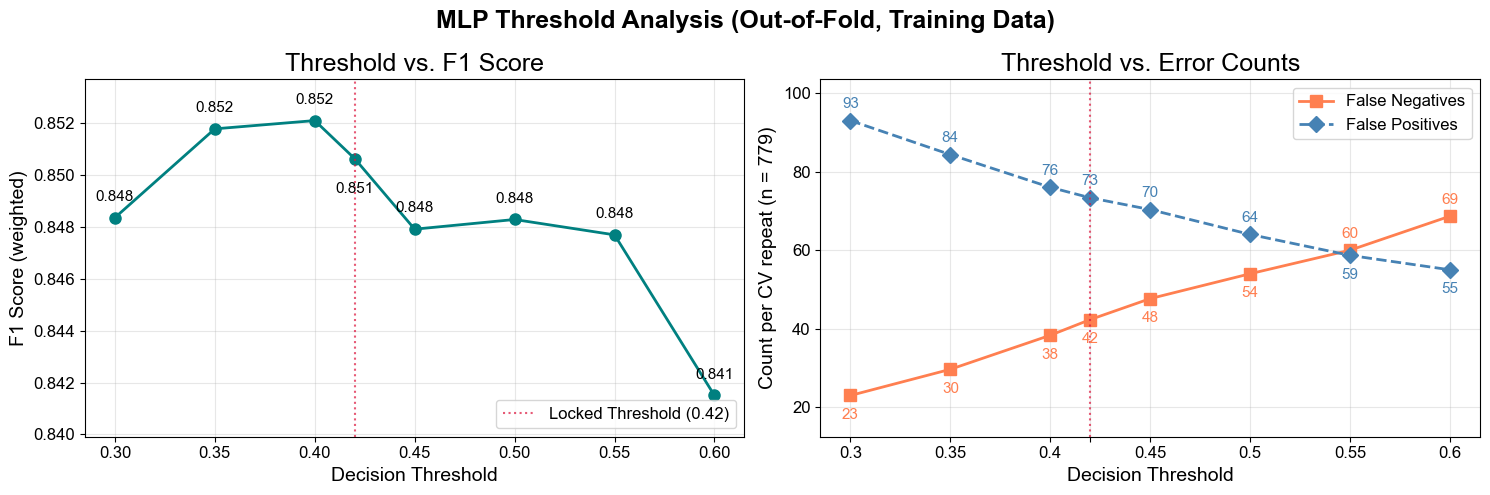

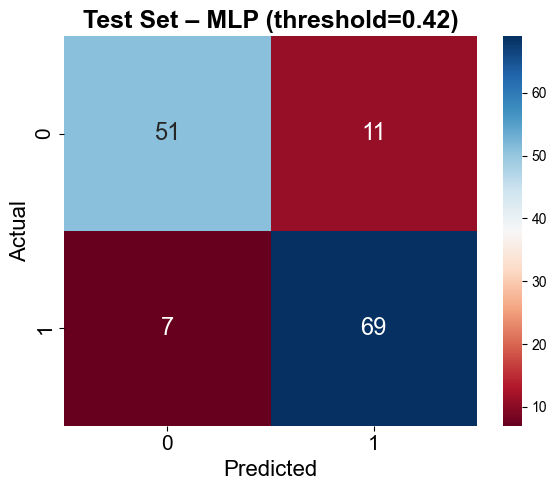

In [ ]:
# Figure: threshold analysis (out-of-fold, training data) + confusion matrix (test set, locked threshold)

p_oof, y_oof = oof_ann
n_rep = len(y_oof) // len(y_dev)                              # number of CV repeats pooled (3)
LOCK = float(LOCKED_ANN)
thresholds = sorted(set([0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60] + [LOCK]))
f1_scores, false_neg, false_pos = [], [], []
for t in thresholds:
    pred = (p_oof >= t).astype(int)
    f1_scores.append(f1_score(y_oof, pred, average="weighted"))
    false_neg.append(((pred == 0) & (y_oof == 1)).sum() / n_rep)   # average count per CV repeat
    false_pos.append(((pred == 1) & (y_oof == 0)).sum() / n_rep)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# --- Left: Threshold vs F1 ---
ax1.plot(thresholds, f1_scores, 'o-', color='teal', linewidth=2, markersize=8)
ax1.set_xlabel('Decision Threshold', fontsize=14); ax1.set_ylabel('F1 Score (weighted)', fontsize=14)
ax1.set_title('Threshold vs. F1 Score', fontsize=18)
ax1.tick_params(axis='both', labelsize=12); ax1.grid(alpha=0.3)
ax1.axvline(x=LOCK, color='crimson', linestyle=':', linewidth=1.5, alpha=0.7, label=f'Locked Threshold ({LOCK:.2f})')
ax1.legend(fontsize=12, loc='lower right')
for x, y_ in zip(thresholds, f1_scores):
    below = np.isclose(x, LOCK)                      # only the locked threshold goes under
    ax1.annotate(
        f'{y_:.3f}', (x, y_),
        textcoords="offset points",
        xytext=(0, -17 if below else 10),
        va='top' if below else 'bottom',
        ha='center', fontsize=11
    )
ax1.margins(y=0.15)

# --- Right: Threshold vs FN and FP ---
ax2.plot(thresholds, false_neg, 's-',  color='coral',     linewidth=2, markersize=8, label='False Negatives')
ax2.plot(thresholds, false_pos, 'D--', color='steelblue', linewidth=2, markersize=8, label='False Positives')
ax2.set_xlabel('Decision Threshold', fontsize=14); ax2.set_ylabel('Count per CV repeat (n = 779)', fontsize=14)
ax2.set_title('Threshold vs. Error Counts', fontsize=18)
ax2.set_xticks(thresholds); ax2.tick_params(axis='both', labelsize=12)
ax2.set_xticklabels(["" if np.isclose(i, LOCK) else i for i in thresholds])
ax2.grid(alpha=0.3)
ax2.axvline(x=LOCK, color='crimson', linestyle=':', linewidth=1.5, alpha=0.7)
ax2.legend(fontsize=12); ax2.margins(y=0.15)
for x, fn, fp in zip(thresholds, false_neg, false_pos):      # the higher line's label goes above, the lower line's below
    up, down = (9, -17)
    ax2.annotate(f'{fn:.0f}', (x, fn), textcoords="offset points", xytext=(0, up if fn >= fp else down), ha='center', color='coral',     fontsize=11)
    ax2.annotate(f'{fp:.0f}', (x, fp), textcoords="offset points", xytext=(0, up if fp > fn else down), ha='center', color='steelblue', fontsize=11)

plt.suptitle('MLP Threshold Analysis (Out-of-Fold, Training Data)', fontsize=18, fontweight='bold')
plt.tight_layout(); plt.savefig(OUT_DIR_FIG / "fig4_mlp_threshold.png", dpi=300); plt.show()

# --- Confusion matrix on the TEST set at the locked threshold (the single evaluation) ---
cm_test = confusion_matrix(y_t, (test_prob_ann >= LOCK).astype(int), labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="RdBu", annot_kws={"size": 17})
plt.title(f"Test Set – MLP (threshold={LOCK:.2f})", fontsize=18, fontweight="bold")
plt.xlabel("Predicted", fontsize=16); plt.ylabel("Actual", fontsize=16)
plt.xticks(fontsize=15); plt.yticks(fontsize=15)
plt.tight_layout(); plt.savefig(OUT_DIR_FIG / "fig4_mlp_confusion.png", dpi=300); plt.show()

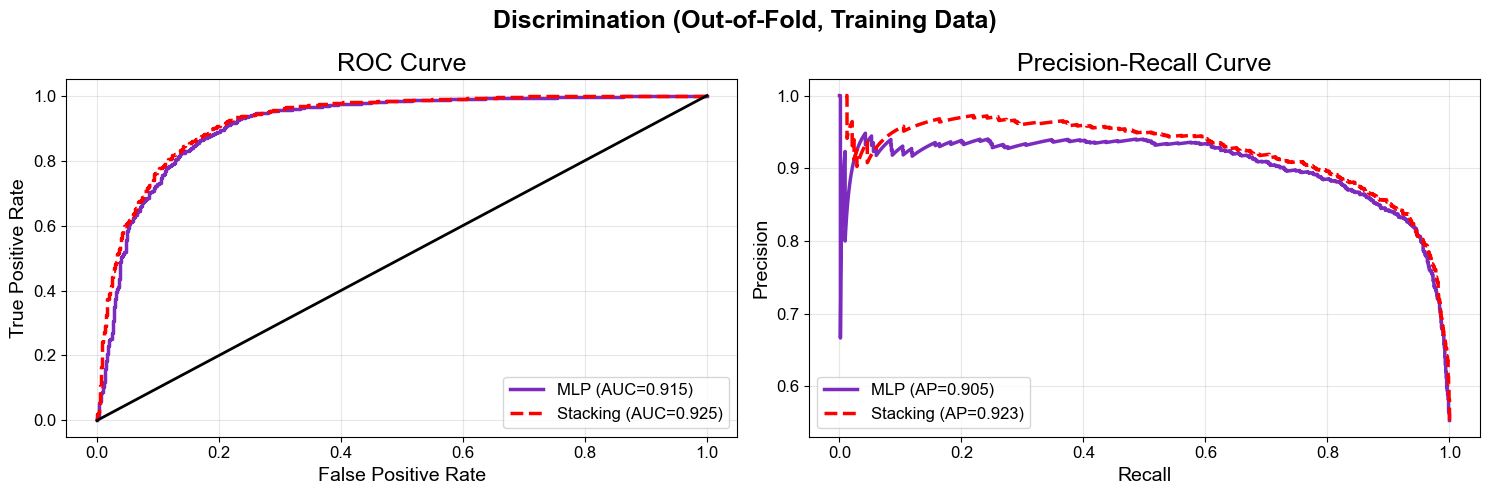

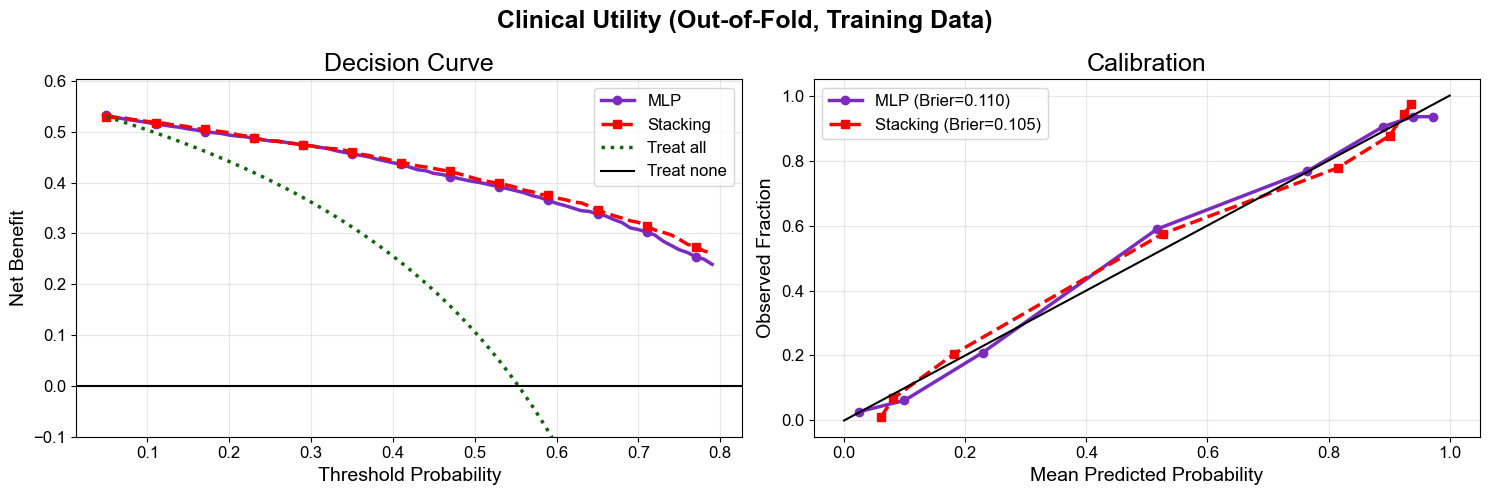

In [36]:
#--------------------------------------------------------
# MLP vs Stacking (out-of-fold): ROC/PR, decision curve, calibration
#--------------------------------------------------------

# color, line style, marker (decision curve), marker (calibration)
STYLE_CMP = {"MLP": ("#7b2cbf", "-", "o", "o"), "Stacking": ("#ff0000", "--", "s", "s")}
cmp_oof = {"MLP": oof_ann, "Stacking": oof["Stacking"]}

# ---- Discrimination ----
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for n, (p, y) in cmp_oof.items():
    c, ls, _, _ = STYLE_CMP[n]
    fpr, tpr, _ = roc_curve(y, p)
    ax[0].plot(fpr, tpr, color=c, ls=ls, linewidth=2.5, label=f"{n} (AUC={roc_auc_score(y, p):.3f})")
    pr, rc, _ = precision_recall_curve(y, p)
    ax[1].plot(rc, pr, color=c, ls=ls, linewidth=2.5, label=f"{n} (AP={average_precision_score(y, p):.3f})")

ax[0].plot([0, 1], [0, 1], color="k", ls="-", linewidth=2)
ax[0].set_xlabel("False Positive Rate", fontsize=14); ax[0].set_ylabel("True Positive Rate", fontsize=14); ax[0].set_title("ROC Curve", fontsize=18)
ax[1].set_xlabel("Recall", fontsize=14); ax[1].set_ylabel("Precision", fontsize=14); ax[1].set_title("Precision-Recall Curve", fontsize=18)
for a in ax:
    a.tick_params(axis="both", labelsize=12); a.grid(alpha=0.3); a.legend(fontsize=12, loc="lower right" if a is ax[0] else "lower left")
plt.suptitle("Discrimination (Out-of-Fold, Training Data)", fontsize=18, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT_DIR_FIG / "fig_mlp_roc_pr_oof.png", dpi=300); plt.show()

# ---- Clinical utility ----
def net_benefit(y, p, t):
    pr = p >= t; n = len(y); tp = (pr & (y == 1)).sum(); fp = (pr & (y == 0)).sum()
    return tp / n - fp / n * t / (1 - t)

ts = np.arange(0.05, 0.80, 0.01)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for n, (p, y) in cmp_oof.items():
    c, ls, m_dca, m_cal = STYLE_CMP[n]
    ax[0].plot(ts, [net_benefit(y, p, t) for t in ts], color=c, ls=ls, marker=m_dca, markevery=6, markersize=6, linewidth=2.5, label=n)
    fo, mp = calibration_curve(y, p, n_bins=8, strategy="quantile")
    ax[1].plot(mp, fo, color=c, ls=ls, marker=m_cal, markersize=6, linewidth=2.5, label=f"{n} (Brier={brier_score_loss(y, p):.3f})")

prev = oof_ann[1].mean()
ax[0].plot(ts, [prev - (1 - prev) * t / (1 - t) for t in ts], color="#11680b", ls=":", linewidth=2.5, label="Treat all")
ax[0].axhline(0, color="black", linewidth=1.5, label="Treat none")
ax[0].set_ylim(-0.1, prev + 0.05)
ax[0].set_xlabel("Threshold Probability", fontsize=14); ax[0].set_ylabel("Net Benefit", fontsize=14); ax[0].set_title("Decision Curve", fontsize=18)
ax[1].plot([0, 1], [0, 1], color="k", ls="-", linewidth=1.5)
ax[1].set_xlabel("Mean Predicted Probability", fontsize=14); ax[1].set_ylabel("Observed Fraction", fontsize=14); ax[1].set_title("Calibration", fontsize=18)
for a in ax:
    a.tick_params(axis="both", labelsize=12); a.grid(alpha=0.3); a.legend(fontsize=12)
plt.suptitle("Clinical Utility (Out-of-Fold, Training Data)", fontsize=18, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT_DIR_FIG / "fig_mlp_dca_calibration.png", dpi=300); plt.show()

In [37]:
#--------------------------------------------
# Save the final MLP (Keras model, preprocessor, locked threshold)
#--------------------------------------------

final_ann.named_steps["model"].model_.save(PROJECT_ROOT / "Models/Classification/mlp_final.keras")
joblib.dump(final_ann.named_steps["preproc"], PROJECT_ROOT / "Models/Classification/mlp_preprocessor.joblib")
joblib.dump({"MLP": LOCKED_ANN}, PROJECT_ROOT / "Models/Classification/locked_threshold_mlp.joblib")

['F:\\Desktop\\Projects\\AI-ML-DL\\Medical-Healthcare-Prediction-Framework\\Models\\Classification\\locked_threshold_mlp.joblib']